# Clasificación de especies de árboles urbanos con LiDAR y aprendizaje profundo

Proyecto final de la Electiva en Ingeniería de Software de la Universidad de San Buenaventura Cali, hecho por Julian David Fuentes Granja.

Este notebook entrena a un computador para que reconozca la especie de un árbol a partir de un escaneo en 3D tomado desde un avión. Usa 152 árboles de seis especies distintas, prueba tres redes neuronales y las compara con un método clásico para ver cuál acierta más.

El código está publicado en https://github.com/JDav19/arbolado-urbantree3d

Para correrlo en Colab hay que elegir la GPU T4 en el tipo de entorno de ejecución y darle a Ejecutar todo, y tarda unas dos horas.

## 1. Preparación del entorno

Esta parte instala lo que hace falta, carga las librerías y revisa si hay una GPU disponible para entrenar más rápido.

In [1]:
import os, sys, json, time, glob, shutil, subprocess, urllib.request, zipfile
MODO_RAPIDO = os.environ.get("MODO_RAPIDO", "0") == "1"   # solo para pruebas, en el informe va en False
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "laspy"], check=True)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import laspy
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from scipy.stats import binomtest, t as dist_t

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo", DISPOSITIVO,
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU")
print("Python", sys.version.split()[0], "| modo rápido", MODO_RAPIDO)

PyTorch 2.14.1+cu130 | dispositivo cuda | Tesla T4
Python 3.13.16 | modo rápido False


Los resultados se guardan en Google Drive para no perderlos si la sesión de Colab se cierra. Colab pide permiso para entrar a Drive una sola vez, y si no se da ese permiso los resultados se guardan en una carpeta temporal de la sesión.

In [2]:
RAIZ = os.path.abspath("arbolado")
if EN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        RAIZ = "/content/drive/MyDrive/arbolado_resultados_v2"
    except Exception as e:
        print("No se montó Drive, se usa almacenamiento local:", e)
        RAIZ = "/content/arbolado_v2"
if MODO_RAPIDO:
    RAIZ = os.path.abspath("arbolado_prueba")
DATOS = os.path.join(RAIZ, "datos")
RES = os.path.join(RAIZ, "resultados")
FIG = os.path.join(RAIZ, "figuras")
for d in (DATOS, RES, FIG):
    os.makedirs(d, exist_ok=True)
print("Carpeta de trabajo", RAIZ)

Mounted at /content/drive
Carpeta de trabajo /content/drive/MyDrive/arbolado_resultados_v2


## 2. Descarga del dataset UrbanTree3D

El dataset está publicado en Zenodo con el DOI 10.5281/zenodo.19475932 y tiene licencia CC BY 4.0, que permite usarlo libremente siempre que se cite a sus autores. Esta celda busca los archivos del dataset en Zenodo, los descarga y descomprime las nubes de puntos, que vienen en formato LAS. Si la descarga falla se pueden subir a mano los archivos `UrbanTree3D_Dataset.rar` y `tree_metadata_training_model.csv` a la carpeta `datos`.

In [3]:
REGISTRO = "19475932"
META_CSV = os.path.join(DATOS, "tree_metadata_training_model.csv")
RAR = os.path.join(DATOS, "UrbanTree3D_Dataset.rar")
LAS_DIR = os.path.join(DATOS, "las")

def descargar_zenodo():
    with urllib.request.urlopen(f"https://zenodo.org/api/records/{REGISTRO}", timeout=60) as r:
        info = json.load(r)
    for f in info["files"]:
        nombre, url = f["key"], f["links"]["self"]
        destino = os.path.join(DATOS, nombre)
        if not os.path.exists(destino):
            print("descargando", nombre)
            urllib.request.urlretrieve(url, destino)

if not (os.path.exists(META_CSV) and os.path.exists(RAR)):
    try:
        descargar_zenodo()
    except Exception as e:
        print("No se pudo descargar desde Zenodo:", e)
print(sorted(os.listdir(DATOS)))

descargando UrbanTree3D_Dataset.rar
descargando trees_metadata_UrbanTree3D.xlsx
descargando tree_metadata_training_model.csv
['UrbanTree3D_Dataset.rar', 'tree_metadata_training_model.csv', 'trees_metadata_UrbanTree3D.xlsx']


In [4]:
def descomprimir_rar(rar, destino):
    os.makedirs(destino, exist_ok=True)
    for cmd in (["unrar", "e", "-o+", "-inul", rar, destino + "/"],
                ["bsdtar", "-xf", rar, "-C", destino],
                ["7z", "e", "-y", f"-o{destino}", rar]):
        if shutil.which(cmd[0]):
            subprocess.run(cmd, check=True)
            return
    if EN_COLAB:
        subprocess.run(["apt-get", "-qq", "install", "-y", "unrar"], check=True)
        subprocess.run(["unrar", "e", "-o+", "-inul", rar, destino + "/"], check=True)
        return
    raise RuntimeError("No hay una herramienta para abrir archivos .rar (unrar, bsdtar o 7z)")

if not glob.glob(os.path.join(LAS_DIR, "**", "*.las"), recursive=True):
    descomprimir_rar(RAR, LAS_DIR)
RUTAS_LAS = {os.path.basename(p): p for p in glob.glob(os.path.join(LAS_DIR, "**", "*.las"), recursive=True)}
print("archivos LAS encontrados", len(RUTAS_LAS))

archivos LAS encontrados 152


## 3. Lectura y exploración del dataset

Aquí se lee la nube de puntos de cada árbol y se revisa cuántos árboles hay de cada especie, cuántos puntos tiene cada árbol y qué altura tienen.

In [5]:
meta = pd.read_csv(META_CSV)
ESPECIES = ["Aesculus hippocastanum", "Prunus serrulata", "Pyrus calleryana",
            "Salix alba", "Tilia platyphyllos", "Tilia × europaea"]
CORTO = ["A. hippocastanum", "P. serrulata", "P. calleryana", "S. alba", "T. platyphyllos", "T. × europaea"]
C = len(ESPECIES)

nubes = []
for f in meta["filename"]:
    las = laspy.read(RUTAS_LAS[f])
    nubes.append(np.column_stack([
        np.asarray(las.x, float), np.asarray(las.y, float), np.asarray(las.z, float),
        np.asarray(las.intensity, float), np.asarray(las.return_number, float),
        np.asarray(las.number_of_returns, float)]))

y_todo = meta["class"].values.astype(int)
particion = meta["train_val"].values
n_puntos = np.array([len(n) for n in nubes])
alturas = np.array([n[:, 2].max() - n[:, 2].min() for n in nubes])

print(f"Árboles {len(nubes)} | puntos por árbol min {n_puntos.min()} mediana {np.median(n_puntos):.0f} "
      f"media {n_puntos.mean():.0f} max {n_puntos.max()}")
altura_campo = meta["tree_H"].values.astype(float)
print(f"Altura de la nube (z max menos z min) min {alturas.min():.1f} m media {alturas.mean():.1f} m max {alturas.max():.1f} m")
print(f"Altura del inventario (columna tree_H) min {altura_campo.min():.1f} m media {altura_campo.mean():.1f} m "
      f"max {altura_campo.max():.1f} m")
tabla = pd.crosstab(pd.Series([ESPECIES[c] for c in y_todo], name="especie"),
                    pd.Series(particion, name="partición"), margins=True, margins_name="total")
tabla[["train", "val", "test", "total"]]

Árboles 152 | puntos por árbol min 61 mediana 429 media 847 max 3739
Altura de la nube (z max menos z min) min 1.8 m media 7.4 m max 17.2 m
Altura del inventario (columna tree_H) min 3.1 m media 8.9 m max 16.8 m


partición,train,val,test,total
especie,,,,
Aesculus hippocastanum,43,9,10,62
Prunus serrulata,8,2,2,12
Pyrus calleryana,10,2,3,15
Salix alba,16,3,4,23
Tilia platyphyllos,17,4,4,25
Tilia × europaea,10,2,3,15
total,104,22,26,152


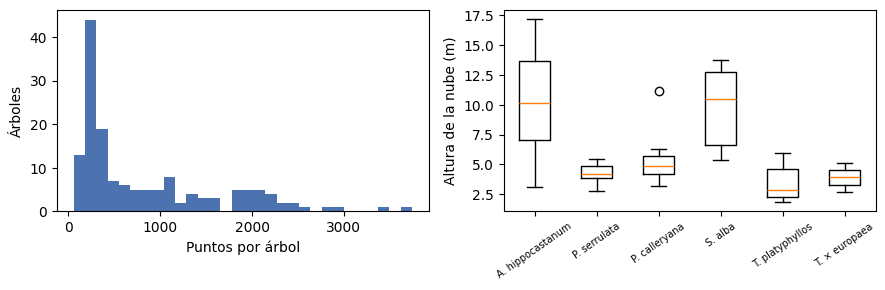

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(n_puntos, bins=30, color="#4C72B0")
ax[0].set_xlabel("Puntos por árbol"); ax[0].set_ylabel("Árboles")
ax[1].boxplot([alturas[y_todo == c] for c in range(C)])
ax[1].set_xticks(range(1, C + 1)); ax[1].set_xticklabels(CORTO)
ax[1].set_ylabel("Altura de la nube (m)"); ax[1].tick_params(axis="x", rotation=35, labelsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "exploracion.pdf")); plt.show()

## 4. Preparación de los datos

Antes de entrar a la red, cada árbol se mueve para que su centro quede en el origen y se escala para que quepa en una esfera de radio 1, así la red aprende la forma del árbol y no su tamaño. Cada árbol se representa con un número fijo de puntos, y si tiene menos de los necesarios se repiten puntos al azar hasta completarlos.

Durante el entrenamiento cada árbol se modifica un poco en cada época para que la red vea más variedad y no se aprenda los ejemplos de memoria. El árbol se gira al azar alrededor del eje vertical, se estira o se encoge entre 0.85 y 1.15 veces, recibe un poco de ruido y pierde hasta el 20 % de sus puntos. En validación y en prueba los árboles no se modifican y siempre se usan los mismos puntos.

Cuando la red también recibe los datos del sensor, cada punto lleva tres valores más. El primero es la intensidad del láser en escala logarítmica y normalizada con los árboles de entrenamiento, el segundo es el número de eco del punto dividido entre el total de ecos de su pulso y el tercero es ese total de ecos dividido entre 8.

In [7]:
def estad_intensidad(indices):
    v = np.log1p(np.concatenate([nubes[i][:, 3] for i in indices]))
    return float(v.mean()), float(v.std())

def entrada(nube, n, rng, atributos, est):
    xyz = nube[:, :3] - nube[:, :3].mean(0, keepdims=True)
    xyz = xyz / np.linalg.norm(xyz, axis=1).max()
    idx = rng.choice(len(xyz), n, replace=len(xyz) < n)
    x = xyz[idx]
    if atributos:
        a = np.column_stack([(np.log1p(nube[idx, 3]) - est[0]) / est[1],
                             nube[idx, 4] / nube[idx, 5], nube[idx, 5] / 8.0])
        x = np.concatenate([x, a], axis=1)
    return x.astype(np.float32)

def aumentar(x, rng):
    # x tiene forma (B, N, D) y las tres primeras columnas son las coordenadas
    x = x.copy()
    B, N, _ = x.shape
    t = rng.uniform(0, 2 * np.pi, B)
    R = np.zeros((B, 3, 3)); R[:, 0, 0] = np.cos(t); R[:, 0, 1] = -np.sin(t)
    R[:, 1, 0] = np.sin(t); R[:, 1, 1] = np.cos(t); R[:, 2, 2] = 1
    xyz = np.einsum("bij,bnj->bni", R, x[..., :3])
    xyz = xyz * rng.uniform(0.85, 1.15, (B, 1, 3)) + rng.normal(0, 0.01, (B, N, 3))
    x[..., :3] = xyz
    descarte = rng.random((B, N)) < rng.uniform(0, 0.2, (B, 1))
    x[descarte] = np.repeat(x[:, :1, :], N, axis=1)[descarte]
    return x.astype(np.float32)

## 5. Las redes neuronales

Las tres redes están programadas en PyTorch. PointNet es la más sencilla, porque procesa cada punto por separado y después resume todo el árbol tomando el valor máximo de cada característica. PointNet++ elige varios puntos centrales, agrupa hasta 32 vecinos que estén dentro de un radio alrededor de cada uno y aprende la forma de esas zonas pequeñas en dos niveles. DGCNN conecta cada punto con sus 16 vecinos más cercanos formando un grafo y vuelve a calcular esas conexiones en cada capa. Al final las tres usan la misma parte de clasificación, que es la que entrega la especie.

In [8]:
def cabeza(entrada, act):
    return nn.Sequential(
        nn.Linear(entrada, 512, bias=False), nn.BatchNorm1d(512), act(), nn.Dropout(0.4),
        nn.Linear(512, 256, bias=False), nn.BatchNorm1d(256), act(), nn.Dropout(0.4),
        nn.Linear(256, C))

class PointNet(nn.Module):
    def __init__(self, d=3):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Conv1d(d, 64, 1, bias=False), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, 1, bias=False), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Conv1d(128, 1024, 1, bias=False), nn.BatchNorm1d(1024), nn.ReLU())
        self.fc = cabeza(1024, nn.ReLU)
    def forward(self, x):                       # x (B, D, N)
        return self.fc(self.mlp(x).max(dim=2)[0])

def dist2(a, b):
    return (a ** 2).sum(-1, keepdim=True) - 2 * a @ b.transpose(1, 2) + (b ** 2).sum(-1).unsqueeze(1)

def muestreo_fps(xyz, m):
    B, N, _ = xyz.shape
    idx = torch.zeros(B, m, dtype=torch.long, device=xyz.device)
    dist = torch.full((B, N), 1e10, device=xyz.device)
    lejano = torch.zeros(B, dtype=torch.long, device=xyz.device)
    ar = torch.arange(B, device=xyz.device)
    for i in range(m):
        idx[:, i] = lejano
        d = ((xyz - xyz[ar, lejano].unsqueeze(1)) ** 2).sum(-1)
        dist = torch.minimum(dist, d)
        lejano = dist.argmax(dim=1)
    return idx

def tomar(x, idx):
    B = x.shape[0]
    ar = torch.arange(B, device=x.device).view(B, *([1] * (idx.dim() - 1))).expand_as(idx)
    return x[ar, idx]

class AbstraccionConjuntos(nn.Module):
    def __init__(self, centros, radio, k, canales):
        super().__init__()
        self.centros, self.radio, self.k = centros, radio, k
        capas, previo = [], canales[0]
        for c in canales[1:]:
            capas += [nn.Conv2d(previo, c, 1, bias=False), nn.BatchNorm2d(c), nn.ReLU()]
            previo = c
        self.mlp = nn.Sequential(*capas)
    def forward(self, xyz, feat):
        nuevo = tomar(xyz, muestreo_fps(xyz, self.centros))
        # Consulta por radio como en el PointNet++ original. Se toman los primeros k puntos dentro
        # de la esfera según el orden de la nube, que es aleatorio porque viene del muestreo.
        # Con k vecinos más cercanos, una nube sobremuestreada con reemplazo entrega k copias
        # del mismo punto y la región local pierde su geometría.
        N = xyz.shape[1]
        fuera = dist2(nuevo, xyz) > self.radio ** 2
        orden = torch.arange(N, device=xyz.device).expand_as(fuera).clone()
        orden[fuera] = N
        vec = orden.sort(dim=-1)[0][..., :self.k]
        vec = torch.where(vec == N, vec[..., :1].expand_as(vec), vec)
        g = tomar(xyz, vec) - nuevo.unsqueeze(2)
        if feat is not None:
            g = torch.cat([g, tomar(feat, vec)], dim=-1)
        g = self.mlp(g.permute(0, 3, 1, 2)).max(dim=-1)[0]
        return nuevo, g.transpose(1, 2)

class PointNetPP(nn.Module):
    def __init__(self, d=3):
        super().__init__()
        self.extra = d - 3
        self.sa1 = AbstraccionConjuntos(256, 0.2, 32, [3 + self.extra, 64, 64, 128])
        self.sa2 = AbstraccionConjuntos(64, 0.4, 32, [128 + 3, 128, 128, 256])
        self.glob = nn.Sequential(
            nn.Conv1d(256 + 3, 256, 1, bias=False), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Conv1d(256, 512, 1, bias=False), nn.BatchNorm1d(512), nn.ReLU(),
            nn.Conv1d(512, 1024, 1, bias=False), nn.BatchNorm1d(1024), nn.ReLU())
        self.fc = cabeza(1024, nn.ReLU)
    def forward(self, x):
        p = x.transpose(1, 2).contiguous()
        xyz, feat = p[..., :3].contiguous(), (p[..., 3:].contiguous() if self.extra else None)
        x1, f1 = self.sa1(xyz, feat)
        x2, f2 = self.sa2(x1, f1)
        return self.fc(self.glob(torch.cat([x2, f2], dim=-1).transpose(1, 2)).max(dim=2)[0])

def knn(x, k):
    inner = -2 * torch.matmul(x.transpose(2, 1), x)
    xx = (x ** 2).sum(dim=1, keepdim=True)
    return (-xx - inner - xx.transpose(2, 1)).topk(k=k, dim=-1)[1]

def rasgos_grafo(x, k):
    B, D, N = x.shape
    idx = (knn(x, k) + torch.arange(B, device=x.device).view(-1, 1, 1) * N).view(-1)
    xt = x.transpose(2, 1).contiguous()
    vec = xt.view(B * N, -1)[idx].view(B, N, k, D)
    centro = xt.view(B, N, 1, D).expand(-1, -1, k, -1)
    return torch.cat([vec - centro, centro], dim=3).permute(0, 3, 1, 2).contiguous()

class DGCNN(nn.Module):
    def __init__(self, d=3, k=16):
        super().__init__()
        self.k = k
        bloque = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 1, bias=False), nn.BatchNorm2d(o), nn.LeakyReLU(0.2))
        self.e1, self.e2, self.e3 = bloque(2 * d, 64), bloque(128, 64), bloque(128, 128)
        self.emb = nn.Sequential(nn.Conv1d(256, 1024, 1, bias=False), nn.BatchNorm1d(1024), nn.LeakyReLU(0.2))
        self.fc = cabeza(2048, lambda: nn.LeakyReLU(0.2))
    def forward(self, x):
        x1 = self.e1(rasgos_grafo(x, self.k)).max(dim=-1)[0]
        x2 = self.e2(rasgos_grafo(x1, self.k)).max(dim=-1)[0]
        x3 = self.e3(rasgos_grafo(x2, self.k)).max(dim=-1)[0]
        e = self.emb(torch.cat([x1, x2, x3], dim=1))
        return self.fc(torch.cat([e.max(dim=2)[0], e.mean(dim=2)], dim=1))

REDES = {"PointNet": PointNet, "PointNet++": PointNetPP, "DGCNN": DGCNN}
for nombre, cls in REDES.items():
    print(f"{nombre:11s} parámetros {sum(p.numel() for p in cls().parameters()) / 1e6:.2f} M")

PointNet    parámetros 0.80 M
PointNet++  parámetros 1.46 M
DGCNN       parámetros 1.47 M


## 6. Entrenamiento y métricas

Como hay especies con muchos más árboles que otras, la función de pérdida les da más peso a los errores en las especies con pocos árboles. El peso de cada especie se calcula con la raíz cuadrada de la razón entre el promedio de árboles por especie y los árboles que tiene esa especie.

Las redes se entrenan con el optimizador Adam durante 100 épocas y en grupos de 16 árboles. La tasa de aprendizaje empieza en 0.001 y baja poco a poco siguiendo una curva coseno, y se usa un decaimiento de pesos de 0.0001 para que los pesos de la red no crezcan demasiado.

Después de cada época se mide el F1 macro con los árboles de validación y se guarda la versión de la red que mejor resultado tuvo. El conjunto de validación es pequeño y el F1 llega a 1.0 en varias épocas, así que cuando hay empate se elige la época con mejor exactitud, y si el empate sigue se elige la de menor pérdida.

Para medir los resultados se usan tres métricas. La exactitud es el porcentaje de árboles bien clasificados, el F1 macro da el mismo peso a todas las especies aunque unas tengan más árboles que otras y la exactitud balanceada promedia el porcentaje de aciertos de cada especie.

Cada entrenamiento se guarda en un archivo JSON con un nombre que dice a qué experimento pertenece, y si ese archivo ya existe el notebook lo carga en lugar de entrenar otra vez.

In [9]:
EPOCAS = 3 if MODO_RAPIDO else 100
LOTE = 16
SEMILLAS = [0, 5, 95]

def metricas(pred, real):
    cm = np.zeros((C, C), dtype=int)
    for r, p in zip(real, pred):
        cm[r, p] += 1
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(0), 1)
    rec = tp / np.maximum(cm.sum(1), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-9), 0.0)
    return dict(acc=float(tp.sum() / cm.sum()), f1_macro=float(f1.mean()), acc_bal=float(rec.mean()),
                f1_clase=f1.tolist(), cm=cm.tolist())

def logits(modelo, x):
    modelo.eval()
    salida = []
    with torch.no_grad():
        for i in range(0, len(x), 16):
            xb = torch.from_numpy(x[i:i + 16]).transpose(1, 2).contiguous().to(DISPOSITIVO)
            salida.append(modelo(xb).cpu())
    return torch.cat(salida)

def predecir(modelo, x):
    return logits(modelo, x).argmax(1).numpy()

def entrenar_red(red, idx_tr, idx_va, idx_te, semilla, n=1024, atributos=False):
    torch.manual_seed(semilla); np.random.seed(semilla)
    rng = np.random.default_rng(semilla)
    est = estad_intensidad(idx_tr)
    fijo = np.random.default_rng(1234)
    x_va = np.stack([entrada(nubes[i], n, fijo, atributos, est) for i in idx_va])
    x_te = np.stack([entrada(nubes[i], n, fijo, atributos, est) for i in idx_te])
    y_tr, y_va, y_te = y_todo[idx_tr], y_todo[idx_va], y_todo[idx_te]
    modelo = REDES[red](d=6 if atributos else 3).to(DISPOSITIVO)
    frec = np.bincount(y_tr, minlength=C)
    pesos = torch.tensor(np.sqrt(frec.sum() / (C * np.maximum(frec, 1))), dtype=torch.float32, device=DISPOSITIVO)
    perdida = nn.CrossEntropyLoss(weight=pesos)
    opt = torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCAS)
    mejor, estado, curva, t0 = (-1.0, -1.0, -np.inf), None, [], time.time()
    y_va_t = torch.from_numpy(y_va)
    for ep in range(EPOCAS):
        modelo.train()
        orden, total = rng.permutation(len(idx_tr)), 0.0
        for i in range(0, len(orden), LOTE):
            b = orden[i:i + LOTE]
            if len(b) < 2:
                continue
            x = np.stack([entrada(nubes[idx_tr[j]], n, rng, atributos, est) for j in b])
            x = torch.from_numpy(aumentar(x, rng)).transpose(1, 2).contiguous().to(DISPOSITIVO)
            opt.zero_grad()
            loss = perdida(modelo(x), torch.from_numpy(y_tr[b]).to(DISPOSITIVO))
            loss.backward(); opt.step()
            total += loss.item() * len(b)
        sched.step()
        lv = logits(modelo, x_va)
        perdida_va = float(nn.functional.cross_entropy(lv, y_va_t))
        mv = metricas(lv.argmax(1).numpy(), y_va)
        curva.append([ep + 1, total / len(idx_tr), mv["acc"], mv["f1_macro"], perdida_va])
        # Con 22 árboles de validación el F1 se satura en 1.0 en muchas épocas.
        # El empate se resuelve con la exactitud y después con la menor pérdida de validación.
        clave = (mv["f1_macro"], mv["acc"], -perdida_va)
        if clave > mejor:
            mejor = clave
            estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
            epoca_elegida = ep + 1
    modelo.load_state_dict(estado)
    pt = predecir(modelo, x_te)
    return dict(val=metricas(predecir(modelo, x_va), y_va), test=metricas(pt, y_te),
                pred_test=pt.tolist(), idx_test=list(map(int, idx_te)), curva=curva, epoca_elegida=epoca_elegida,
                parametros=int(sum(p.numel() for p in modelo.parameters())), tiempo_s=time.time() - t0)

def con_cache(clave, funcion):
    ruta = os.path.join(RES, clave + ".json")
    if os.path.exists(ruta):
        return json.load(open(ruta))
    r = funcion()
    json.dump(r, open(ruta, "w"))
    print(f"  {clave}: test acc {r['test']['acc']:.3f} F1 {r['test']['f1_macro']:.3f} "
          f"| val F1 {r['val']['f1_macro']:.3f} | {r.get('tiempo_s', 0):.0f} s", flush=True)
    return r

### Método de referencia, el bosque aleatorio

El bosque aleatorio es un método clásico que junta las respuestas de 500 árboles de decisión, trabaja con medidas calculadas a mano sobre cada árbol y les da más peso a las especies con pocos ejemplos. La versión sin escala usa 27 medidas que no dependen del tamaño del árbol, como la forma en que se reparten los puntos según la altura, la forma de la copa y los valores promedio de intensidad y de retornos. La versión con escala agrega cuatro medidas de tamaño, que son la altura, el ancho de la copa, la relación entre los dos y el número de puntos, para un total de 31.

In [10]:
def descriptores(nube):
    xyz, inten = nube[:, :3], nube[:, 3]
    z = xyz[:, 2] - xyz[:, 2].min()
    xy = xyz[:, :2] - xyz[:, :2].mean(axis=0)
    altura = z.max()
    ax_, ay_ = np.ptp(xy[:, 0]), np.ptp(xy[:, 1])
    radio = np.linalg.norm(xy, axis=1)
    zn = z / max(altura, 1e-6)
    hist = np.histogram(zn, bins=10, range=(0, 1))[0] / len(zn)
    ev = np.sort(np.linalg.eigvalsh(np.cov((xyz - xyz.mean(0)).T)))[::-1]
    ev = ev / ev.sum()
    sin_escala = np.concatenate([np.percentile(zn, [10, 25, 50, 75, 90]), hist, ev, [
        radio.mean() / max(radio.max(), 1e-6), radio.std() / max(radio.max(), 1e-6),
        min(ax_, ay_) / max(ax_, ay_, 1e-6), zn.mean(), zn.std(),
        inten.mean() / 1000.0, inten.std() / 1000.0, nube[:, 4].mean(), nube[:, 5].mean()]])
    escala = np.array([altura, max(ax_, ay_), altura / max(ax_, ay_, 1e-6), np.log(len(z))])
    return np.concatenate([escala, sin_escala]), sin_escala

DESC = [descriptores(n) for n in nubes]
X_RF = {"RF con escala": np.stack([d[0] for d in DESC]), "RF sin escala": np.stack([d[1] for d in DESC])}
print({k: v.shape[1] for k, v in X_RF.items()}, "descriptores")

def entrenar_rf(variante, idx_tr, idx_va, idx_te, semilla):
    X = X_RF[variante]
    rf = RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=semilla, n_jobs=-1)
    t0 = time.time()
    rf.fit(X[idx_tr], y_todo[idx_tr])
    pt = rf.predict(X[idx_te])
    return dict(val=metricas(rf.predict(X[idx_va]), y_todo[idx_va]), test=metricas(pt, y_todo[idx_te]),
                pred_test=pt.tolist(), idx_test=list(map(int, idx_te)), tiempo_s=time.time() - t0,
                importancias=rf.feature_importances_.tolist())

{'RF con escala': 31, 'RF sin escala': 27} descriptores


## 7. Experimento 1, la división oficial del dataset

Este experimento usa la división de datos que trae el dataset, con 104 árboles para entrenar, 22 para validar y 26 para la prueba. Cada método se entrena tres veces con las semillas 0, 5 y 95, que son las mismas que usaron los autores del dataset, y se reporta el promedio de las tres.

In [11]:
IDX = {p: np.where(particion == p)[0] for p in ("train", "val", "test")}
METODOS_E1 = ["RF con escala", "RF sin escala", "PointNet", "PointNet++", "DGCNN"]
E1 = {m: {} for m in METODOS_E1}
for s in SEMILLAS:
    for m in METODOS_E1:
        if m.startswith("RF"):
            E1[m][s] = con_cache(f"e1_{m.replace(' ', '_')}_s{s}",
                                 lambda: entrenar_rf(m, IDX["train"], IDX["val"], IDX["test"], s))
        else:
            E1[m][s] = con_cache(f"e1_{m}_n1024_xyz_s{s}",
                                 lambda: entrenar_red(m, IDX["train"], IDX["val"], IDX["test"], s))

  e1_RF_con_escala_s0: test acc 0.885 F1 0.884 | val F1 0.812 | 2 s
  e1_RF_sin_escala_s0: test acc 0.885 F1 0.887 | val F1 0.794 | 2 s
  e1_PointNet_n1024_xyz_s0: test acc 0.923 F1 0.936 | val F1 0.957 | 27 s
  e1_PointNet++_n1024_xyz_s0: test acc 0.846 F1 0.800 | val F1 0.847 | 60 s
  e1_DGCNN_n1024_xyz_s0: test acc 0.962 F1 0.967 | val F1 1.000 | 72 s
  e1_RF_con_escala_s5: test acc 0.885 F1 0.870 | val F1 0.812 | 1 s
  e1_RF_sin_escala_s5: test acc 0.923 F1 0.916 | val F1 0.794 | 2 s
  e1_PointNet_n1024_xyz_s5: test acc 0.923 F1 0.936 | val F1 1.000 | 12 s
  e1_PointNet++_n1024_xyz_s5: test acc 0.885 F1 0.873 | val F1 0.879 | 57 s
  e1_DGCNN_n1024_xyz_s5: test acc 0.962 F1 0.967 | val F1 0.957 | 72 s
  e1_RF_con_escala_s95: test acc 0.846 F1 0.838 | val F1 0.837 | 1 s
  e1_RF_sin_escala_s95: test acc 0.923 F1 0.916 | val F1 0.851 | 2 s
  e1_PointNet_n1024_xyz_s95: test acc 0.923 F1 0.936 | val F1 1.000 | 12 s
  e1_PointNet++_n1024_xyz_s95: test acc 0.769 F1 0.771 | val F1 0.779 | 5

In [12]:
def resumen(dic_semillas, parte="test"):
    v = lambda k: np.array([r[parte][k] for r in dic_semillas.values()])
    return {k: (v(k).mean(), v(k).std(ddof=1) if len(v(k)) > 1 else 0.0) for k in ("acc", "f1_macro", "acc_bal")}

def fila(nombre, dic):
    t, va = resumen(dic, "test"), resumen(dic, "val")
    return {"Método": nombre,
            **{f"{k} prueba": f"{t[k][0]:.3f} ± {t[k][1]:.3f}" for k in ("acc", "f1_macro", "acc_bal")},
            **{f"{k} validación": f"{va[k][0]:.3f} ± {va[k][1]:.3f}" for k in ("acc", "f1_macro")}}

tabla_e1 = pd.DataFrame([fila(m, E1[m]) for m in METODOS_E1])
tabla_e1

,Método,acc prueba,f1_macro prueba,acc_bal prueba,acc validación,f1_macro validación
0,RF con escala,0.872 ± 0.022,0.864 ± 0.023,0.872 ± 0.024,0.864 ± 0.000,0.821 ± 0.014
1,RF sin escala,0.910 ± 0.022,0.906 ± 0.016,0.922 ± 0.010,0.833 ± 0.026,0.813 ± 0.033
2,PointNet,0.923 ± 0.000,0.936 ± 0.000,0.942 ± 0.000,0.985 ± 0.026,0.986 ± 0.025
3,PointNet++,0.833 ± 0.059,0.815 ± 0.052,0.851 ± 0.063,0.879 ± 0.052,0.835 ± 0.051
4,DGCNN,0.962 ± 0.000,0.964 ± 0.005,0.983 ± 0.000,0.985 ± 0.026,0.986 ± 0.025


In [13]:
f1c = pd.DataFrame({m: np.mean([r["test"]["f1_clase"] for r in E1[m].values()], axis=0) for m in METODOS_E1},
                   index=CORTO).T.round(2)
print("F1 por especie en prueba, promedio de tres semillas")
f1c

F1 por especie en prueba, promedio de tres semillas


,A. hippocastanum,P. serrulata,P. calleryana,S. alba,T. platyphyllos,T. × europaea
RF con escala,0.92,1.00,0.71,0.90,0.80,0.86
RF sin escala,0.93,1.00,0.80,0.96,0.89,0.86
PointNet,0.90,1.00,0.86,0.86,1.00,1.00
PointNet++,0.85,0.82,0.70,0.80,0.96,0.76
DGCNN,0.95,0.93,0.95,1.00,1.00,0.95


## 8. Experimento 2, cantidad de puntos por árbol

Los autores del dataset entrenaron PointNet++ con 8 192 puntos por árbol. Aquí se prueban PointNet y PointNet++ con 1 024, 2 048, 4 096 y 8 192 puntos para ver si más puntos ayudan. Hay que tener en cuenta que la mitad de los árboles tiene 429 puntos o menos, así que con muestras grandes casi todos los puntos son repetidos.

In [14]:
PUNTOS = [1024, 2048] if MODO_RAPIDO else [1024, 2048, 4096, 8192]
E2 = {m: {1024: E1[m]} for m in ("PointNet", "PointNet++")}
for m in E2:
    for n in PUNTOS[1:]:
        E2[m][n] = {s: con_cache(f"e2_{m}_n{n}_xyz_s{s}",
                                 lambda: entrenar_red(m, IDX["train"], IDX["val"], IDX["test"], s, n=n))
                    for s in SEMILLAS}

filas = []
for m in E2:
    for n in PUNTOS:
        t = resumen(E2[m][n]); va = resumen(E2[m][n], "val")
        filas.append({"Red": m, "Puntos": n, "Exact. prueba": f"{t['acc'][0]:.3f} ± {t['acc'][1]:.3f}",
                      "F1 prueba": f"{t['f1_macro'][0]:.3f} ± {t['f1_macro'][1]:.3f}",
                      "Exact. validación": f"{va['acc'][0]:.3f} ± {va['acc'][1]:.3f}",
                      "Tiempo medio (s)": f"{np.mean([r['tiempo_s'] for r in E2[m][n].values()]):.0f}"})
tabla_e2 = pd.DataFrame(filas)
tabla_e2

  e2_PointNet_n2048_xyz_s0: test acc 0.923 F1 0.936 | val F1 1.000 | 20 s
  e2_PointNet_n2048_xyz_s5: test acc 0.923 F1 0.888 | val F1 0.966 | 20 s
  e2_PointNet_n2048_xyz_s95: test acc 0.923 F1 0.936 | val F1 1.000 | 21 s
  e2_PointNet_n4096_xyz_s0: test acc 0.962 F1 0.967 | val F1 1.000 | 38 s
  e2_PointNet_n4096_xyz_s5: test acc 0.885 F1 0.871 | val F1 1.000 | 38 s
  e2_PointNet_n4096_xyz_s95: test acc 0.923 F1 0.893 | val F1 1.000 | 38 s
  e2_PointNet_n8192_xyz_s0: test acc 0.923 F1 0.936 | val F1 1.000 | 77 s
  e2_PointNet_n8192_xyz_s5: test acc 0.962 F1 0.967 | val F1 1.000 | 78 s
  e2_PointNet_n8192_xyz_s95: test acc 0.923 F1 0.926 | val F1 1.000 | 77 s
  e2_PointNet++_n2048_xyz_s0: test acc 0.808 F1 0.724 | val F1 0.856 | 62 s
  e2_PointNet++_n2048_xyz_s5: test acc 0.885 F1 0.869 | val F1 1.000 | 62 s
  e2_PointNet++_n2048_xyz_s95: test acc 0.885 F1 0.872 | val F1 0.883 | 62 s
  e2_PointNet++_n4096_xyz_s0: test acc 0.846 F1 0.822 | val F1 0.868 | 74 s
  e2_PointNet++_n4096_xyz_

,Red,Puntos,Exact. prueba,F1 prueba,Exact. validación,Tiempo medio (s)
0,PointNet,1024,0.923 ± 0.000,0.936 ± 0.000,0.985 ± 0.026,17
1,PointNet,2048,0.923 ± 0.000,0.920 ± 0.028,0.985 ± 0.026,21
2,PointNet,4096,0.923 ± 0.038,0.910 ± 0.051,1.000 ± 0.000,38
3,PointNet,8192,0.936 ± 0.022,0.943 ± 0.022,1.000 ± 0.000,77
4,PointNet++,1024,0.833 ± 0.059,0.815 ± 0.052,0.879 ± 0.052,58
5,PointNet++,2048,0.859 ± 0.044,0.822 ± 0.085,0.939 ± 0.052,62
6,PointNet++,4096,0.872 ± 0.022,0.842 ± 0.017,0.909 ± 0.000,74
7,PointNet++,8192,0.769 ± 0.102,0.743 ± 0.119,0.848 ± 0.026,138


## 9. Experimento 3, coordenadas más datos del sensor

El bosque aleatorio usa la intensidad y los retornos del láser, mientras que en el experimento 1 las redes solo recibieron las coordenadas. En este experimento las tres redes reciben seis valores por punto, las tres coordenadas más los tres datos del sensor, para que la comparación con el bosque aleatorio sea justa.

In [15]:
E3 = {}
for m in REDES:
    E3[m] = {s: con_cache(f"e3_{m}_n1024_attr_s{s}",
                          lambda: entrenar_red(m, IDX["train"], IDX["val"], IDX["test"], s, atributos=True))
             for s in SEMILLAS}
filas = []
for m in REDES:
    for etiqueta, dic in (("solo xyz", E1[m]), ("xyz + intensidad y retornos", E3[m])):
        t = resumen(dic)
        filas.append({"Red": m, "Entrada": etiqueta, "Exact. prueba": f"{t['acc'][0]:.3f} ± {t['acc'][1]:.3f}",
                      "F1 prueba": f"{t['f1_macro'][0]:.3f} ± {t['f1_macro'][1]:.3f}",
                      "Exact. balanc.": f"{t['acc_bal'][0]:.3f} ± {t['acc_bal'][1]:.3f}"})
tabla_e3 = pd.DataFrame(filas)
tabla_e3

  e3_PointNet_n1024_attr_s0: test acc 1.000 F1 1.000 | val F1 1.000 | 13 s
  e3_PointNet_n1024_attr_s5: test acc 1.000 F1 1.000 | val F1 1.000 | 13 s
  e3_PointNet_n1024_attr_s95: test acc 1.000 F1 1.000 | val F1 1.000 | 13 s
  e3_PointNet++_n1024_attr_s0: test acc 0.962 F1 0.948 | val F1 1.000 | 58 s
  e3_PointNet++_n1024_attr_s5: test acc 1.000 F1 1.000 | val F1 1.000 | 58 s
  e3_PointNet++_n1024_attr_s95: test acc 0.962 F1 0.967 | val F1 1.000 | 58 s
  e3_DGCNN_n1024_attr_s0: test acc 0.962 F1 0.973 | val F1 1.000 | 74 s
  e3_DGCNN_n1024_attr_s5: test acc 0.962 F1 0.933 | val F1 1.000 | 74 s
  e3_DGCNN_n1024_attr_s95: test acc 1.000 F1 1.000 | val F1 1.000 | 74 s


,Red,Entrada,Exact. prueba,F1 prueba,Exact. balanc.
0,PointNet,solo xyz,0.923 ± 0.000,0.936 ± 0.000,0.942 ± 0.000
1,PointNet,xyz + intensidad y retornos,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
2,PointNet++,solo xyz,0.833 ± 0.059,0.815 ± 0.052,0.851 ± 0.063
3,PointNet++,xyz + intensidad y retornos,0.974 ± 0.022,0.972 ± 0.026,0.976 ± 0.029
4,DGCNN,solo xyz,0.962 ± 0.000,0.964 ± 0.005,0.983 ± 0.000
5,DGCNN,xyz + intensidad y retornos,0.974 ± 0.022,0.969 ± 0.034,0.976 ± 0.029


## 10. Experimento 4, validación cruzada repetida

Con solo 26 árboles de prueba un error cambia la exactitud en 3.8 puntos, y eso hace que los resultados de la división oficial dependan mucho de qué árboles quedaron en la prueba. Para tener una medida más confiable se usan los 152 árboles y se dividen en cinco grupos que tienen la misma proporción de especies. Cada grupo se usa una vez como prueba, y de los árboles restantes se aparta un 15 % como validación para elegir la mejor época. Todo esto se repite tres veces con divisiones distintas, usando las semillas 0, 1 y 2, así que cada método se entrena 15 veces y cada árbol se clasifica tres veces como dato de prueba.

In [16]:
N_PLIEGUES = 2 if MODO_RAPIDO else 5
REPETICIONES = 1 if MODO_RAPIDO else 3
PLIEGUES = []                                   # lista de (repetición, pliegue, tr, va, te)
for rep in range(REPETICIONES):
    skf = StratifiedKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=rep)
    for k, (resto, te) in enumerate(skf.split(np.zeros(len(y_todo)), y_todo)):
        tr, va = train_test_split(resto, test_size=0.15, stratify=y_todo[resto], random_state=100 * rep + k)
        PLIEGUES.append((rep, k, tr, va, te))

METODOS_CV = {"RF con escala": ("rf", None), "RF sin escala": ("rf", None),
              "PointNet": ("red", False), "PointNet++": ("red", False), "DGCNN": ("red", False),
              "PointNet + atrib.": ("red", True), "PointNet++ + atrib.": ("red", True), "DGCNN + atrib.": ("red", True)}
E4 = {m: [[] for _ in range(REPETICIONES)] for m in METODOS_CV}
for rep, k, tr, va, te in PLIEGUES:
    print(f"repetición {rep + 1} de {REPETICIONES}, pliegue {k + 1} de {N_PLIEGUES}", flush=True)
    for m, (tipo, atr) in METODOS_CV.items():
        if tipo == "rf":
            r = con_cache(f"e4_{m.replace(' ', '_')}_r{rep}_f{k}", lambda: entrenar_rf(m, tr, va, te, rep))
        else:
            base = m.split(" + ")[0]
            r = con_cache(f"e4_{base}_n1024_{'attr' if atr else 'xyz'}_r{rep}_f{k}",
                          lambda: entrenar_red(base, tr, va, te, rep, atributos=atr))
        E4[m][rep].append(r)

repetición 1 de 3, pliegue 1 de 5
  e4_RF_con_escala_r0_f0: test acc 0.935 F1 0.932 | val F1 0.644 | 1 s
  e4_RF_sin_escala_r0_f0: test acc 0.903 F1 0.881 | val F1 0.662 | 1 s
  e4_PointNet_n1024_xyz_r0_f0: test acc 0.935 F1 0.938 | val F1 0.841 | 12 s
  e4_PointNet++_n1024_xyz_r0_f0: test acc 0.677 F1 0.453 | val F1 0.822 | 58 s
  e4_DGCNN_n1024_xyz_r0_f0: test acc 0.968 F1 0.960 | val F1 0.813 | 70 s
  e4_PointNet_n1024_attr_r0_f0: test acc 0.935 F1 0.930 | val F1 0.892 | 13 s
  e4_PointNet++_n1024_attr_r0_f0: test acc 0.871 F1 0.922 | val F1 0.892 | 58 s
  e4_DGCNN_n1024_attr_r0_f0: test acc 0.903 F1 0.880 | val F1 0.855 | 72 s
repetición 1 de 3, pliegue 2 de 5
  e4_RF_con_escala_r0_f1: test acc 0.871 F1 0.848 | val F1 0.703 | 1 s
  e4_RF_sin_escala_r0_f1: test acc 0.839 F1 0.823 | val F1 0.623 | 1 s
  e4_PointNet_n1024_xyz_r0_f1: test acc 0.871 F1 0.834 | val F1 0.919 | 12 s
  e4_PointNet++_n1024_xyz_r0_f1: test acc 0.774 F1 0.769 | val F1 0.734 | 57 s
  e4_DGCNN_n1024_xyz_r0_f1: t

En cada repetición se juntan las predicciones de los cinco grupos para calcular las métricas sobre los 152 árboles, y la tabla muestra el promedio y la desviación de las tres repeticiones. El intervalo de confianza del 95 % se calcula con la técnica bootstrap, que consiste en sortear los árboles con reemplazo 2 000 veces y ver entre qué valores queda el F1 en el 95 % de esos sorteos.

In [17]:
def agrupar(lista):
    idx = np.concatenate([r["idx_test"] for r in lista])
    pred = np.concatenate([r["pred_test"] for r in lista])
    orden = np.argsort(idx)
    assert (idx[orden] == np.arange(len(y_todo))).all()
    return pred[orden]

PRED_CV = {m: np.stack([agrupar(E4[m][rep]) for rep in range(REPETICIONES)]) for m in METODOS_CV}

def bootstrap(preds, real, B=2000, semilla=0):
    # preds (R, N). En cada remuestreo se promedia la métrica de las R repeticiones.
    rng = np.random.default_rng(semilla)
    acc, f1 = [], []
    for _ in range(B):
        i = rng.integers(0, len(real), len(real))
        ms = [metricas(p[i], real[i]) for p in preds]
        acc.append(np.mean([m["acc"] for m in ms])); f1.append(np.mean([m["f1_macro"] for m in ms]))
    return np.percentile(acc, [2.5, 97.5]), np.percentile(f1, [2.5, 97.5])

def por_repeticion(m, clave):
    return np.array([metricas(p, y_todo)[clave] for p in PRED_CV[m]])

def ms_txt(v):
    return f"{v.mean():.3f} ± {v.std(ddof=1):.3f}" if len(v) > 1 else f"{v.mean():.3f}"

IC = {m: bootstrap(PRED_CV[m], y_todo) for m in METODOS_CV}
filas = []
for m in METODOS_CV:
    ci_a, ci_f = IC[m]
    f1_pl = np.array([r["test"]["f1_macro"] for rep in E4[m] for r in rep])
    filas.append({"Método": m, "Exactitud": ms_txt(por_repeticion(m, "acc")),
                  "IC 95 % exactitud": f"[{ci_a[0]:.3f}, {ci_a[1]:.3f}]",
                  "F1 macro": ms_txt(por_repeticion(m, "f1_macro")), "IC 95 % F1": f"[{ci_f[0]:.3f}, {ci_f[1]:.3f}]",
                  "Exact. balanc.": ms_txt(por_repeticion(m, "acc_bal")),
                  "F1 por pliegue": ms_txt(f1_pl)})
tabla_e4 = pd.DataFrame(filas)
tabla_e4

,Método,Exactitud,IC 95 % exactitud,F1 macro,IC 95 % F1,Exact. balanc.,F1 por pliegue
0,RF con escala,0.877 ± 0.017,"[0.827, 0.921]",0.853 ± 0.014,"[0.784, 0.906]",0.844 ± 0.015,0.848 ± 0.066
1,RF sin escala,0.846 ± 0.014,"[0.792, 0.895]",0.830 ± 0.017,"[0.761, 0.883]",0.815 ± 0.022,0.821 ± 0.061
2,PointNet,0.860 ± 0.017,"[0.816, 0.901]",0.833 ± 0.021,"[0.776, 0.877]",0.847 ± 0.012,0.826 ± 0.101
3,PointNet++,0.772 ± 0.039,"[0.715, 0.820]",0.723 ± 0.045,"[0.653, 0.779]",0.746 ± 0.038,0.708 ± 0.122
4,DGCNN,0.866 ± 0.034,"[0.822, 0.904]",0.841 ± 0.033,"[0.788, 0.882]",0.864 ± 0.035,0.842 ± 0.099
5,PointNet + atrib.,0.928 ± 0.024,"[0.893, 0.956]",0.914 ± 0.030,"[0.868, 0.948]",0.918 ± 0.025,0.905 ± 0.082
6,PointNet++ + atrib.,0.875 ± 0.017,"[0.833, 0.912]",0.858 ± 0.024,"[0.804, 0.901]",0.864 ± 0.039,0.851 ± 0.092
7,DGCNN + atrib.,0.923 ± 0.019,"[0.890, 0.952]",0.910 ± 0.023,"[0.865, 0.943]",0.920 ± 0.026,0.909 ± 0.080


In [18]:
f1c_cv = pd.DataFrame({m: np.mean([metricas(p, y_todo)["f1_clase"] for p in PRED_CV[m]], axis=0) for m in METODOS_CV},
                      index=CORTO).T.round(2)
print("F1 por especie en validación cruzada, promedio de las repeticiones")
f1c_cv

F1 por especie en validación cruzada, promedio de las repeticiones


,A. hippocastanum,P. serrulata,P. calleryana,S. alba,T. platyphyllos,T. × europaea
RF con escala,0.92,0.92,0.76,0.87,0.89,0.74
RF sin escala,0.87,0.92,0.75,0.84,0.89,0.71
PointNet,0.91,0.86,0.62,0.81,0.91,0.89
PointNet++,0.86,0.67,0.56,0.80,0.83,0.62
DGCNN,0.90,0.83,0.65,0.87,0.92,0.87
PointNet + atrib.,0.95,0.92,0.82,0.92,0.92,0.95
PointNet++ + atrib.,0.90,0.88,0.73,0.83,0.89,0.92
DGCNN + atrib.,0.95,0.93,0.83,0.90,0.93,0.91


### Comparación estadística entre métodos

Para saber si un método es mejor que otro de verdad o si la diferencia puede ser casualidad, cada par de métodos se compara con dos pruebas estadísticas.

La primera es la prueba t corregida de Nadeau y Bengio, que compara el F1 de los dos métodos en los 15 entrenamientos. Una prueba t normal mostraría diferencias que no son reales, porque los grupos de entrenamiento de los distintos pliegues comparten muchos árboles, y esta versión corrige ese problema aumentando la varianza según el tamaño de la prueba y del entrenamiento.

La segunda es la prueba de McNemar, que revisa árbol por árbol los casos en que un método acierta y el otro falla, y se aplica por separado en cada una de las tres repeticiones.

Como se comparan 28 pares de métodos, es probable que alguna diferencia parezca importante por pura suerte, y por eso los valores p se ajustan con el método de Holm. Una diferencia se considera real solo si el valor p ajustado queda por debajo de 0.05.

In [19]:
def holm(p):
    p = np.asarray(p, float); m = len(p)
    orden = np.argsort(p)
    ajustado = np.empty(m)
    acumulado = 0.0
    for rango, i in enumerate(orden):
        acumulado = max(acumulado, (m - rango) * p[i])
        ajustado[i] = min(1.0, acumulado)
    return ajustado

def t_corregida(a, b, razon):
    d = np.asarray(a) - np.asarray(b); J = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return 0.0, 1.0
    t = d.mean() / np.sqrt((1 / J + razon) * var)
    return float(t), float(2 * dist_t.sf(abs(t), J - 1))

def mcnemar(a, b, real):
    ok_a, ok_b = a == real, b == real
    n01, n10 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    p = binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 > 0 else 1.0
    return n01, n10, p

n_te = np.mean([len(te) for *_, te in PLIEGUES])
RAZON = n_te / (len(y_todo) - n_te)
F1_PLIEGUES = {m: [r["test"]["f1_macro"] for rep in E4[m] for r in rep] for m in METODOS_CV}

nombres = list(METODOS_CV)
pares = [(nombres[i], nombres[j]) for i in range(len(nombres)) for j in range(i + 1, len(nombres))]
p_t, p_mc = [], [[] for _ in range(REPETICIONES)]
filas = []
for a, b in pares:
    t, p = t_corregida(F1_PLIEGUES[a], F1_PLIEGUES[b], RAZON)
    p_t.append(p)
    n01 = n10 = 0
    for rep in range(REPETICIONES):
        x01, x10, pm = mcnemar(PRED_CV[a][rep], PRED_CV[b][rep], y_todo)
        n01 += x01; n10 += x10; p_mc[rep].append(pm)
    filas.append({"A": a, "B": b, "Dif. F1 (A-B)": round(float(np.mean(F1_PLIEGUES[a]) - np.mean(F1_PLIEGUES[b])), 3),
                  "t": round(t, 2), "p t corregida": p, "solo A acierta": n01, "solo B acierta": n10})
tabla_pares = pd.DataFrame(filas)
tabla_pares["p Holm t"] = holm(p_t)
p_mc_holm = np.array([holm(p) for p in p_mc])            # (R, pares)
tabla_pares["p Holm McNemar (máx. entre repeticiones)"] = p_mc_holm.max(0)
tabla_pares["Repeticiones con McNemar significativo"] = (p_mc_holm < 0.05).sum(0)
tabla_pares["Diferencia significativa"] = np.where(tabla_pares["p Holm t"] < 0.05, "sí", "no")
tabla_pares = tabla_pares.round(4)
tabla_pares

,A,B,Dif. F1 (A-B),t,p t corregida,solo A acierta,solo B acierta,p Holm t,p Holm McNemar (máx. entre repeticiones),Repeticiones con McNemar significativo,Diferencia significativa
0,RF con escala,RF sin escala,0.027,1.51,0.1529,22,8,1.0000,1.0000,0,no
1,RF con escala,PointNet,0.022,0.30,0.7660,36,28,1.0000,1.0000,0,no
2,RF con escala,PointNet++,0.140,1.61,0.1300,77,29,1.0000,0.4633,0,no
3,RF con escala,DGCNN,0.005,0.09,0.9261,33,28,1.0000,1.0000,0,no
4,RF con escala,PointNet + atrib.,-0.057,-1.15,0.2686,15,38,1.0000,1.0000,0,no
5,RF con escala,PointNet++ + atrib.,-0.003,-0.05,0.9588,34,33,1.0000,1.0000,0,no
6,RF con escala,DGCNN + atrib.,-0.061,-1.26,0.2275,14,35,1.0000,1.0000,0,no
7,RF sin escala,PointNet,-0.005,-0.07,0.9426,36,42,1.0000,1.0000,0,no
8,RF sin escala,PointNet++,0.113,1.33,0.2056,81,47,1.0000,1.0000,0,no
9,RF sin escala,DGCNN,-0.021,-0.38,0.7089,33,42,1.0000,1.0000,0,no


## 11. Figuras del informe

Estas celdas dibujan las figuras que aparecen en el informe y las guardan en la carpeta de figuras.

In [20]:
mejor_cv = max([m for m in METODOS_CV if not m.startswith("RF")], key=lambda m: por_repeticion(m, "f1_macro").mean())
print("Red con mejor F1 macro en validación cruzada:", mejor_cv)

Red con mejor F1 macro en validación cruzada: PointNet + atrib.


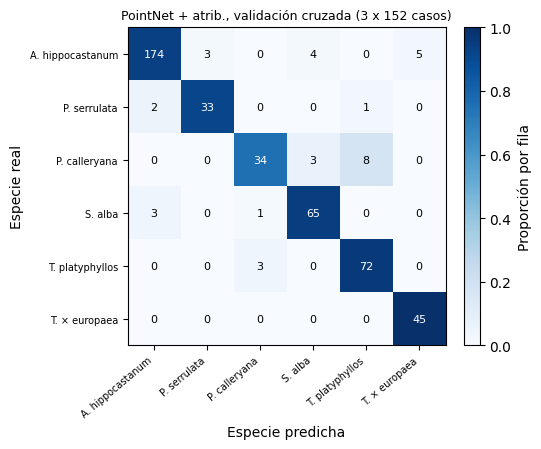

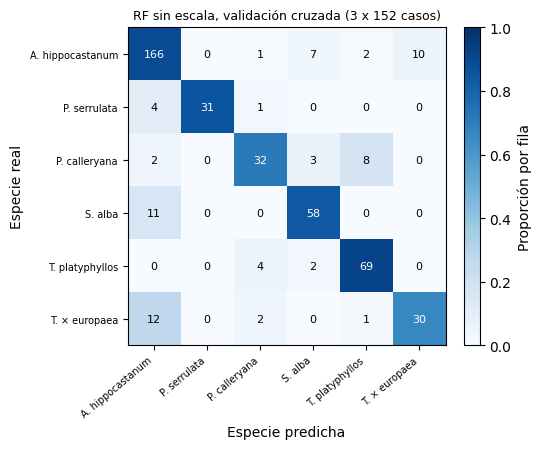

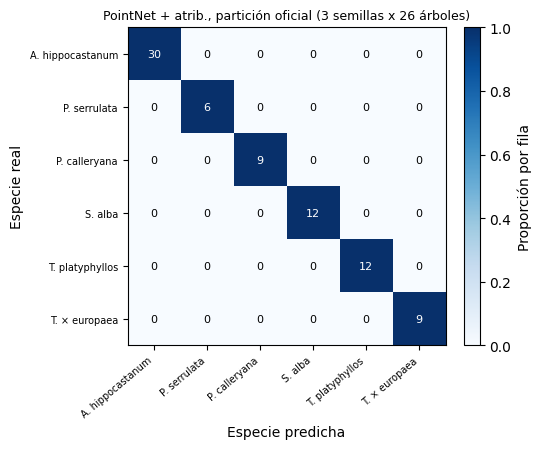

In [21]:
def dibujar_confusion(cm, titulo, archivo):
    cm = np.array(cm); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(5.4, 4.6))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(C)); ax.set_yticks(range(C))
    ax.set_xticklabels(CORTO, rotation=40, ha="right", fontsize=7); ax.set_yticklabels(CORTO, fontsize=7)
    for i in range(C):
        for j in range(C):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xlabel("Especie predicha"); ax.set_ylabel("Especie real"); ax.set_title(titulo, fontsize=9)
    plt.colorbar(im, fraction=0.046, label="Proporción por fila")
    plt.tight_layout(); plt.savefig(os.path.join(FIG, archivo)); plt.show()

cm_cv = lambda m: np.sum([metricas(p, y_todo)["cm"] for p in PRED_CV[m]], axis=0)
dibujar_confusion(cm_cv(mejor_cv), f"{mejor_cv}, validación cruzada ({REPETICIONES} x 152 casos)", "confusion_cv.pdf")
dibujar_confusion(cm_cv("RF sin escala"), f"RF sin escala, validación cruzada ({REPETICIONES} x 152 casos)", "confusion_cv_rf.pdf")
dibujar_confusion(np.sum([r["test"]["cm"] for r in E1[mejor_cv.split(" + ")[0]].values()], axis=0) if "atrib" not in mejor_cv
                  else np.sum([r["test"]["cm"] for r in E3[mejor_cv.split(" + ")[0]].values()], axis=0),
                  f"{mejor_cv}, partición oficial (3 semillas x 26 árboles)", "confusion_oficial.pdf")

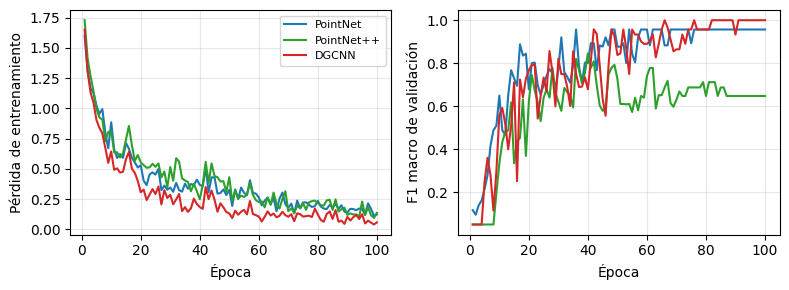

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
colores = {"PointNet": "#1f77b4", "PointNet++": "#2ca02c", "DGCNN": "#d62728"}
for m, c in colores.items():
    cur = np.array(E1[m][0]["curva"])
    ax[0].plot(cur[:, 0], cur[:, 1], color=c, label=m)
    ax[1].plot(cur[:, 0], cur[:, 3], color=c, label=m)
ax[0].set_xlabel("Época"); ax[0].set_ylabel("Pérdida de entrenamiento")
ax[1].set_xlabel("Época"); ax[1].set_ylabel("F1 macro de validación")
for a in ax: a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "curvas.pdf")); plt.show()

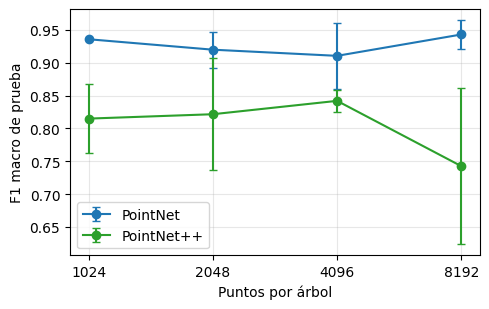

In [23]:
fig, ax = plt.subplots(figsize=(5, 3.2))
for m, c in (("PointNet", "#1f77b4"), ("PointNet++", "#2ca02c")):
    med = [resumen(E2[m][n])["f1_macro"][0] for n in PUNTOS]
    de = [resumen(E2[m][n])["f1_macro"][1] for n in PUNTOS]
    ax.errorbar(PUNTOS, med, yerr=de, marker="o", capsize=3, color=c, label=m)
ax.set_xscale("log", base=2); ax.set_xticks(PUNTOS); ax.set_xticklabels(PUNTOS)
ax.set_xlabel("Puntos por árbol"); ax.set_ylabel("F1 macro de prueba"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG, "puntos.pdf")); plt.show()

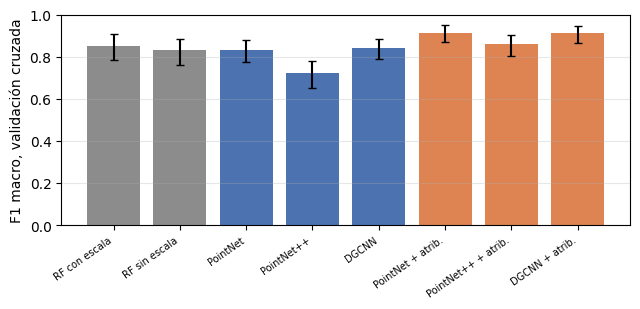

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
orden = list(METODOS_CV)
f1s = [por_repeticion(m, "f1_macro").mean() for m in orden]
ics = [IC[m][1] for m in orden]
err = np.array([[f - ic[0], ic[1] - f] for f, ic in zip(f1s, ics)]).T
col = ["#8c8c8c" if m.startswith("RF") else ("#dd8452" if "atrib" in m else "#4c72b0") for m in orden]
ax.bar(range(len(orden)), f1s, yerr=err, capsize=3, color=col)
ax.set_xticks(range(len(orden))); ax.set_xticklabels(orden, rotation=35, ha="right", fontsize=7)
ax.set_ylabel("F1 macro, validación cruzada"); ax.set_ylim(0, 1); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "cv_f1.pdf")); plt.show()

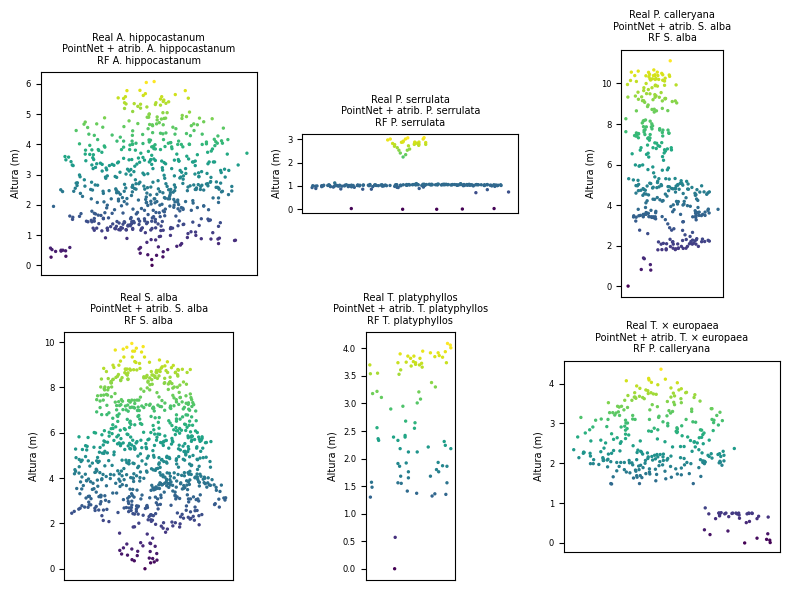

In [25]:
fig, axs = plt.subplots(2, 3, figsize=(8, 6))
pred_red, pred_rf = PRED_CV[mejor_cv][0], PRED_CV["RF sin escala"][0]
for c, ax in enumerate(axs.ravel()):
    k = np.where(y_todo == c)[0][0]
    n = nubes[k]; x = n[:, 0] - n[:, 0].mean(); z = n[:, 2] - n[:, 2].min()
    ax.scatter(x, z, c=z, cmap="viridis", s=2); ax.set_aspect("equal"); ax.set_xticks([])
    ax.set_title(f"Real {CORTO[c]}\n{mejor_cv} {CORTO[pred_red[k]]}\nRF {CORTO[pred_rf[k]]}", fontsize=7)
    ax.set_ylabel("Altura (m)", fontsize=7); ax.tick_params(labelsize=6)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "cualitativo.png"), dpi=200); plt.show()

## 12. Guardado de los resultados

Aquí se guardan las tablas en formato LaTeX y un archivo llamado resumen_final.json con todos los resultados, que es de donde salen las cifras del informe, y al final todo se comprime en un archivo zip.

In [26]:
def a_latex(df, archivo):
    with open(os.path.join(RES, archivo), "w", encoding="utf-8") as f:
        f.write(df.to_latex(index=False, escape=False).replace("±", r"$\pm$"))

for df, nombre in ((tabla_e1, "tabla_e1.tex"), (f1c.reset_index().rename(columns={"index": "Método"}), "tabla_f1_clase.tex"),
                   (tabla_e2, "tabla_e2.tex"), (tabla_e3, "tabla_e3.tex"), (tabla_e4, "tabla_e4.tex"),
                   (f1c_cv.reset_index().rename(columns={"index": "Método"}), "tabla_f1_clase_cv.tex"),
                   (tabla_pares, "tabla_pares.tex")):
    a_latex(df, nombre)

RESUMEN = {
    "entorno": {"torch": torch.__version__, "dispositivo": str(DISPOSITIVO),
                "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
                "epocas": EPOCAS, "semillas": SEMILLAS, "modo_rapido": MODO_RAPIDO},
    "dataset": {"arboles": len(nubes), "puntos_min": int(n_puntos.min()), "puntos_mediana": float(np.median(n_puntos)),
                "puntos_media": float(n_puntos.mean()), "puntos_max": int(n_puntos.max()),
                "altura_nube_min": float(alturas.min()), "altura_nube_media": float(alturas.mean()), "altura_nube_max": float(alturas.max()),
                "altura_inventario_min": float(altura_campo.min()), "altura_inventario_media": float(altura_campo.mean()),
                "altura_inventario_max": float(altura_campo.max())},
    "e1": {m: {"test": resumen(E1[m]), "val": resumen(E1[m], "val"),
               "f1_clase": f1c.loc[m].tolist(),
               "por_semilla": {str(s): {"test_acc": r["test"]["acc"], "test_f1": r["test"]["f1_macro"]} for s, r in E1[m].items()},
               "cm_suma": np.sum([r["test"]["cm"] for r in E1[m].values()], axis=0).tolist(),
               "tiempo_medio_s": float(np.mean([r["tiempo_s"] for r in E1[m].values()])),
               "epoca_elegida": [r.get("epoca_elegida") for r in E1[m].values()],
               "parametros": next(iter(E1[m].values())).get("parametros")} for m in METODOS_E1},
    "e2": {m: {str(n): {"test": resumen(E2[m][n]), "val": resumen(E2[m][n], "val"),
                        "tiempo_medio_s": float(np.mean([r["tiempo_s"] for r in E2[m][n].values()]))}
               for n in PUNTOS} for m in E2},
    "e3": {m: {"test": resumen(E3[m]), "val": resumen(E3[m], "val"),
               "f1_clase": np.mean([r["test"]["f1_clase"] for r in E3[m].values()], axis=0).tolist(),
               "por_semilla": {str(s): {"test_acc": r["test"]["acc"], "test_f1": r["test"]["f1_macro"]} for s, r in E3[m].items()}}
           for m in E3},
    "e4": {m: {"acc": [por_repeticion(m, "acc").mean(), por_repeticion(m, "acc").std(ddof=1) if REPETICIONES > 1 else 0.0],
               "f1_macro": [por_repeticion(m, "f1_macro").mean(), por_repeticion(m, "f1_macro").std(ddof=1) if REPETICIONES > 1 else 0.0],
               "acc_bal": [por_repeticion(m, "acc_bal").mean(), por_repeticion(m, "acc_bal").std(ddof=1) if REPETICIONES > 1 else 0.0],
               "ic_acc": IC[m][0].tolist(), "ic_f1": IC[m][1].tolist(), "f1_clase": f1c_cv.loc[m].tolist(),
               "cm_suma": cm_cv(m).tolist(), "f1_pliegues": F1_PLIEGUES[m], "pred": PRED_CV[m].tolist()} for m in METODOS_CV},
    "comparaciones": tabla_pares.to_dict(orient="records"),
    "razon_nadeau_bengio": RAZON, "repeticiones": REPETICIONES, "pliegues": N_PLIEGUES,
    "mejor_cv": mejor_cv,
}
json.dump(RESUMEN, open(os.path.join(RES, "resumen_final.json"), "w"), indent=1, default=float)
shutil.make_archive(os.path.join(RAIZ, "resultados_arbolado"), "zip", RAIZ, ".",)
print("Resultados guardados en", RAIZ)
print(json.dumps(RESUMEN, default=float))

Resultados guardados en /content/drive/MyDrive/arbolado_resultados_v2
{"entorno": {"torch": "2.14.1+cu130", "dispositivo": "cuda", "gpu": "Tesla T4", "epocas": 100, "semillas": [0, 5, 95], "modo_rapido": false}, "dataset": {"arboles": 152, "puntos_min": 61, "puntos_mediana": 429.0, "puntos_media": 846.6184210526316, "puntos_max": 3739, "altura_nube_min": 1.8300000000000054, "altura_nube_media": 7.440789473684211, "altura_nube_max": 17.17, "altura_inventario_min": 3.104, "altura_inventario_media": 8.939546052631579, "altura_inventario_max": 16.767}, "e1": {"RF con escala": {"test": {"acc": [0.8717948717948718, 0.02220577958421636], "f1_macro": [0.8641836071660632, 0.02327514126650891], "acc_bal": [0.8722222222222222, 0.024056261216234387]}, "val": {"acc": [0.8636363636363636, 0.0], "f1_macro": [0.8206245461147423, 0.014213634078088755], "acc_bal": [0.8425925925925926, 0.0]}, "f1_clase": [0.92, 1.0, 0.71, 0.9, 0.8, 0.86], "por_semilla": {"0": {"test_acc": 0.8846153846153846, "test_f1": 0

## 13. Conclusión

Las tablas de este notebook son las mismas que aparecen en el informe técnico. La división oficial del experimento 1 sirve para comparar con el trabajo de los autores de UrbanTree3D, y la validación cruzada repetida del experimento 4 es la base de la comparación entre métodos, porque evalúa los 152 árboles tres veces y permite calcular intervalos de confianza y pruebas estadísticas. Todas las cifras del informe salen de los resultados de este notebook.